In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/video-games-sales/VideoGames_Sales.xlsx


# Global Video Game Sales Analysis: Trends, Publishers & Hits
**Uncovering Trends, Hits, and Market Leaders in the Gaming Industry**

## Introduction
In this notebook, we perform a deep-dive analysis of the Video Games Sales dataset. We will explore:
* Global sales trends over the years.
* The most successful games and publishers of all time.
* Regional preferences (North America, Europe, Japan).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import re

import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_excel("/kaggle/input/video-games-sales/VideoGames_Sales.xlsx")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64016 entries, 0 to 64015
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   title             64016 non-null  object        
 1   console           64016 non-null  object        
 2   genre             64016 non-null  object        
 3   publisher         64016 non-null  object        
 4   developer         63999 non-null  object        
 5   critic_score      6678 non-null   float64       
 6   total_sales(mil)  18922 non-null  float64       
 7   na_sales(mil)     12637 non-null  float64       
 8   jp_sales(mil)     6726 non-null   float64       
 9   pal_sales(mil)    12824 non-null  float64       
 10  other_sales(mil)  15128 non-null  float64       
 11  release_date      56965 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(6), object(5)
memory usage: 5.9+ MB


In [5]:
print(df.isnull().sum())

title                   0
console                 0
genre                   0
publisher               0
developer              17
critic_score        57338
total_sales(mil)    45094
na_sales(mil)       51379
jp_sales(mil)       57290
pal_sales(mil)      51192
other_sales(mil)    48888
release_date         7051
dtype: int64


In [6]:
df.describe()

,critic_score,total_sales(mil),na_sales(mil),jp_sales(mil),pal_sales(mil),other_sales(mil),release_date
count,6678.000000,18922.000000,12637.000000,6726.000000,12824.000000,15128.000000,56965
mean,7.220440,0.349113,0.264740,0.102281,0.149472,0.043041,2006-11-14 06:33:03.491617792
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1971-12-03 00:00:00
25%,6.400000,0.030000,0.050000,0.020000,0.010000,0.000000,2001-03-28 00:00:00
50%,7.500000,0.120000,0.120000,0.040000,0.040000,0.010000,2008-09-16 00:00:00
75%,8.300000,0.340000,0.280000,0.120000,0.140000,0.030000,2012-12-27 00:00:00
max,10.000000,20.320000,9.760000,2.130000,9.850000,3.120000,2024-12-31 00:00:00
std,1.457066,0.807462,0.494787,0.168811,0.392653,0.126643,NaN


## Analyzing Categorical Variables
We check the distribution of unique values for categorical columns like Platform, Genre, and Publisher to understand the data variety.

In [7]:
categorical_cols = df.select_dtypes(include='object').columns
for col in categorical_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts().head(12))


Column: title
title
Plants vs. Zombies     17
Pac-Man                16
Monopoly               15
Doom                   14
Double Dragon          14
Elite                  14
Samurai Shodown        13
Lemmings               13
Minecraft              13
Resident Evil 4        13
Jeopardy!              13
The Incredible Hulk    12
Name: count, dtype: int64

Column: console
console
PC      12617
PS2      3565
DS       3288
PS4      2878
PS       2707
NS       2337
XBL      2120
PSN      2004
XOne     1963
PS3      1905
PSP      1807
X360     1735
Name: count, dtype: int64

Column: genre
genre
Misc            9304
Action          8557
Adventure       6260
Role-Playing    5721
Sports          5586
Shooter         5410
Platform        4001
Strategy        3685
Puzzle          3521
Racing          3425
Simulation      3158
Fighting        2367
Name: count, dtype: int64

Column: publisher
publisher
Unknown                        8842
Sega                           2207
Ubisoft               

## Data Cleaning: Handling Missing Values
We will handle missing data by:
* Filling missing `critic_score` with the median value.
* Replacing missing categorical data (Publisher, Developer) with 'Unknown'.
* Assuming missing sales figures are 0.

In [8]:
if 'critic_score' in df.columns:
    critic_score_median = df['critic_score'].median()
    df['critic_score'] = df['critic_score'].fillna(critic_score_median)

cols_to_fill_unknown = ['publisher', 'developer']
for col in cols_to_fill_unknown:
    if col in df.columns:
        df[col] = df[col].fillna('Unknown')

sales_cols = ['total_sales(mil)', 'na_sales(mil)', 'jp_sales(mil)', 'pal_sales(mil)', 'other_sales(mil)']
for col in sales_cols:
    if col in df.columns:
        df[col] = df[col].fillna(0)


## Feature Engineering: Date Extraction
To analyze time-series trends, we extract the **Year** and **Month** from the release date.

In [9]:
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['release_year'] = df['release_date'].dt.year
df['release_month'] = df['release_date'].dt.month
df.drop(columns=['release_date'], inplace=True)

df.head()

,title,console,genre,publisher,developer,critic_score,total_sales(mil),na_sales(mil),jp_sales(mil),pal_sales(mil),other_sales(mil),release_year,release_month
0,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,20.32,6.37,0.99,9.85,3.12,2013.0,9.0
1,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,19.39,6.06,0.60,9.71,3.02,2014.0,11.0
2,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,16.15,8.41,0.47,5.49,1.78,2002.0,10.0
3,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,7.5,15.86,9.06,0.06,5.33,1.42,2013.0,9.0
4,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,15.09,6.18,0.41,6.05,2.44,2015.0,11.0


## Visualizing the Giants: Top 20 Best-Selling Games
Which games define the industry? Here are the top 20 titles by global sales across all platforms.

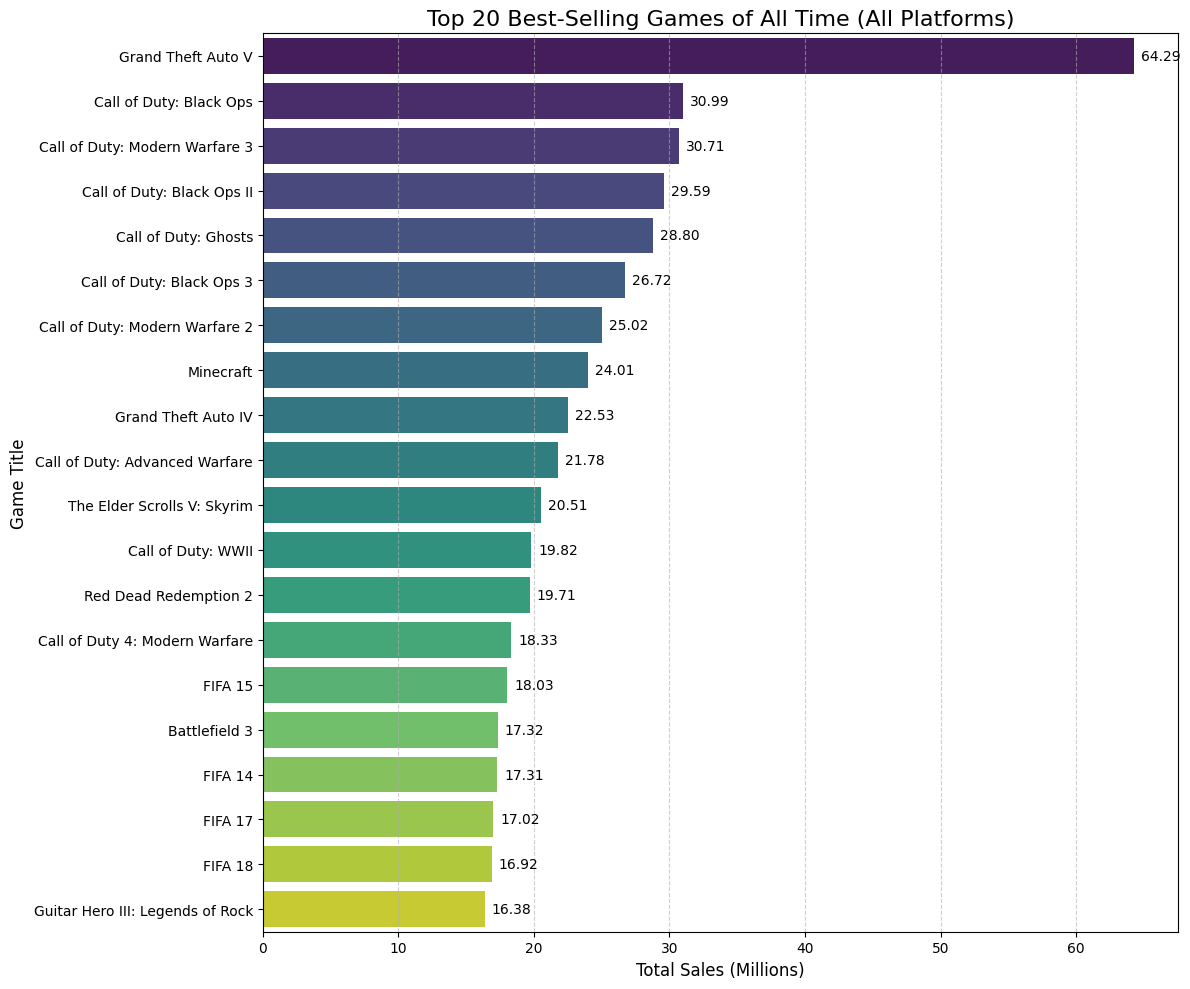

In [10]:
top_games = df.groupby('title')['total_sales(mil)'].sum().sort_values(ascending=False).head(20)

plt.figure(figsize=(12, 10))
ax = sns.barplot(x=top_games.values, y=top_games.index, palette='viridis')

plt.title('Top 20 Best-Selling Games of All Time (All Platforms)', fontsize=16)
plt.xlabel('Total Sales (Millions)', fontsize=12)
plt.ylabel('Game Title', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

for i, v in enumerate(top_games.values):
    ax.text(v + 0.5, i, f'{v:.2f}', color='black', va='center', fontsize=10)

plt.tight_layout()
plt.show()

## Industry Growth: Number of Games Released by Year
Tracking the volume of game releases gives us insight into the industry's boom periods.

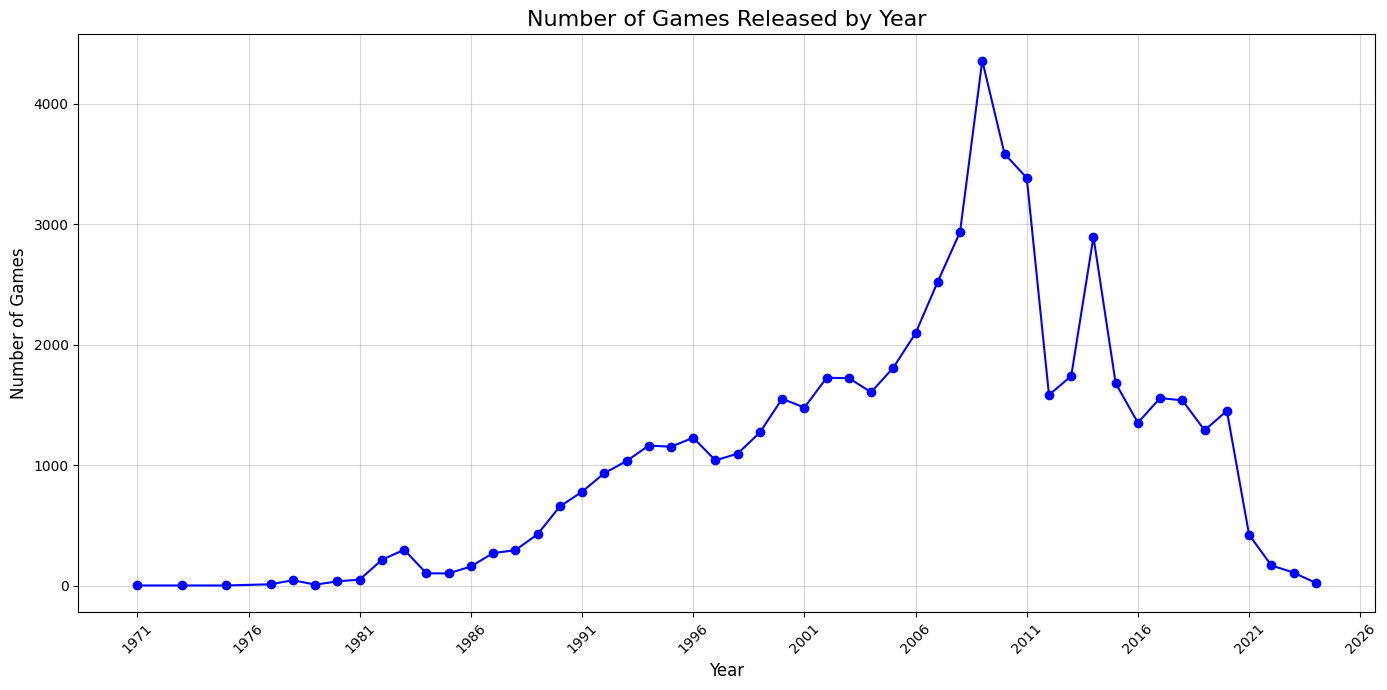

In [11]:
games_per_year = df['release_year'].value_counts().sort_index()

plt.figure(figsize=(14, 7))
plt.plot(games_per_year.index, games_per_year.values, marker='o', linestyle='-', color='b')

plt.title('Number of Games Released by Year', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Games', fontsize=12)

min_year = int(games_per_year.index.min())
max_year = int(games_per_year.index.max())
plt.xticks(np.arange(min_year, max_year + 5, 5), rotation=45)

plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

Sales reached their highest level during the 5-year period between 2006 and 2011. There appears to have been a decline since then.

## Seasonality: Which Month is Best for Gaming?
Do publishers prefer holiday seasons? Let's check the monthly distribution of releases.

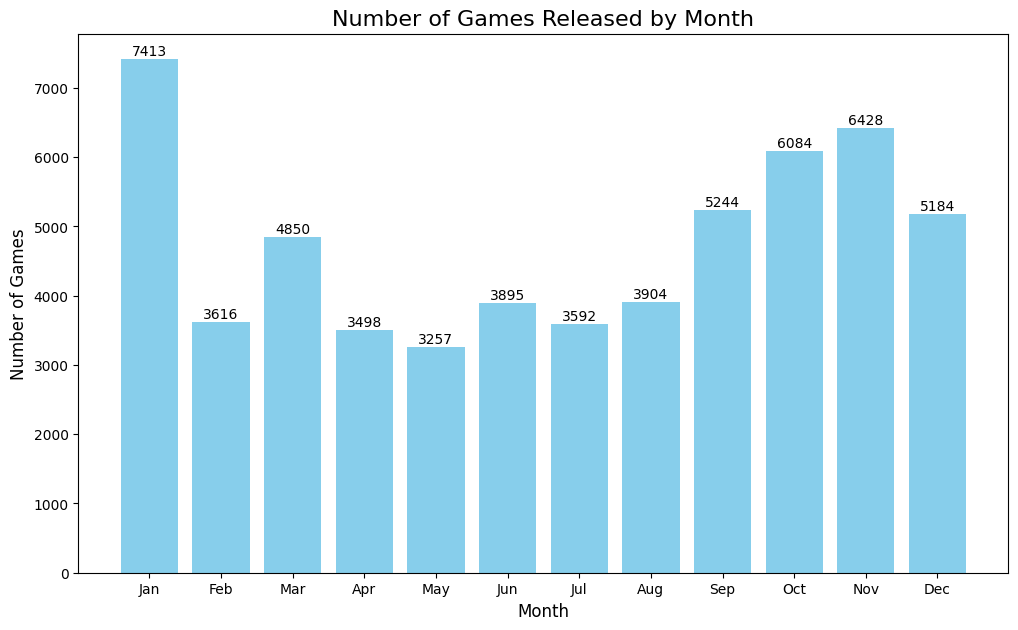

In [12]:
games_per_month = df['release_month'].value_counts().sort_index()

plt.figure(figsize=(12, 7))
bars = plt.bar(games_per_month.index, games_per_month.values, color='skyblue')

plt.title('Number of Games Released by Month', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Games', fontsize=12)
plt.xticks(ticks=range(1, 13), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 10, int(yval), ha='center', va='bottom')

plt.show()


As this graph shows, a large number of games were released in late autumn and winter.

## Sales Trends Over Time
Comparing total sales volume by year and month.

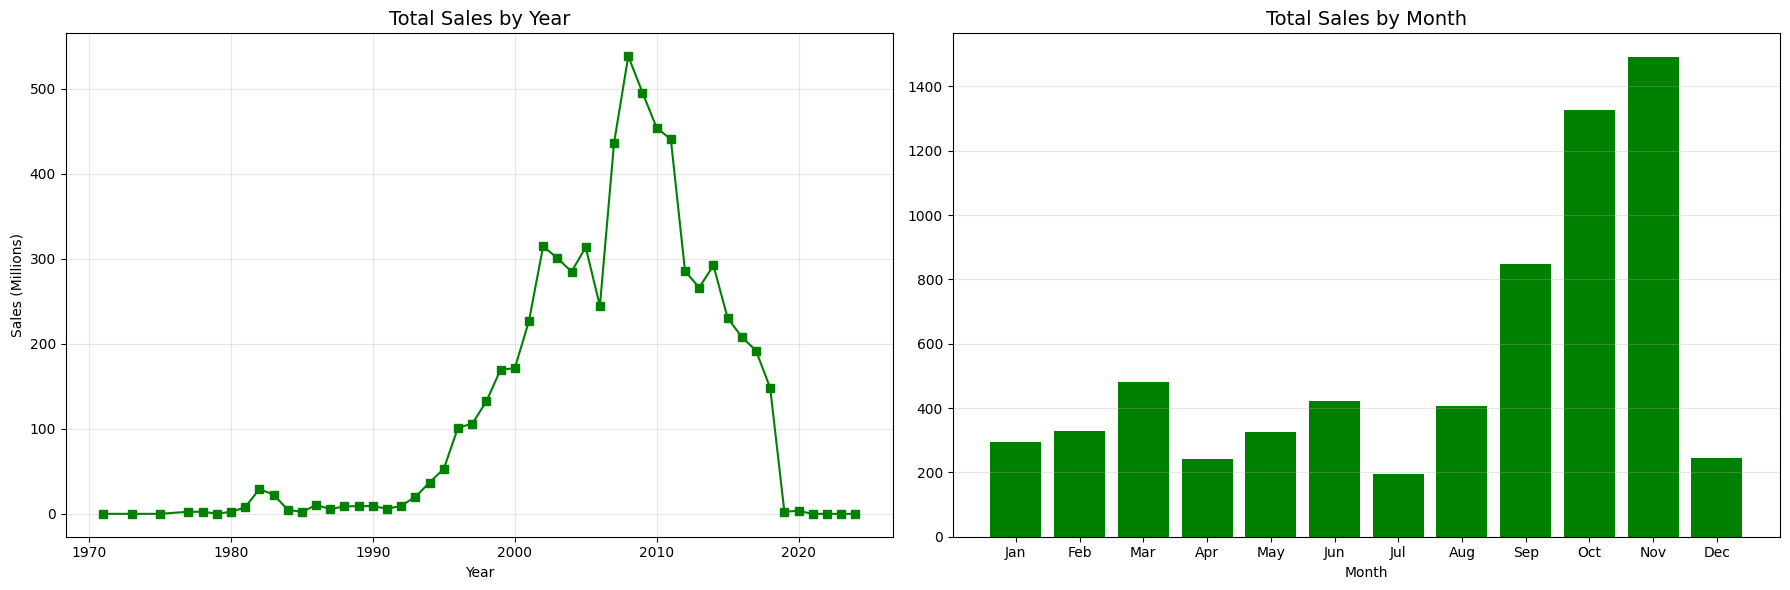

In [13]:
yearly_sales = df.groupby('release_year')['total_sales(mil)'].sum().sort_index()
monthly_sales = df.groupby('release_month')['total_sales(mil)'].sum().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

ax1.plot(yearly_sales.index, yearly_sales.values, color='green', marker='s')
ax1.set_title('Total Sales by Year', fontsize=14)
ax1.set_xlabel('Year')
ax1.set_ylabel('Sales (Millions)')
ax1.grid(True, alpha=0.3)

ax2.bar(monthly_sales.index, monthly_sales.values, color='green')
ax2.set_title('Total Sales by Month', fontsize=14)
ax2.set_xlabel('Month')
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Sales appear to be more concentrated in the late spring months. The years with the highest sales seem to coincide with the period when most games are released.

## Regional: NA vs. JP vs. Europe
How did sales evolve in different major regions over time?

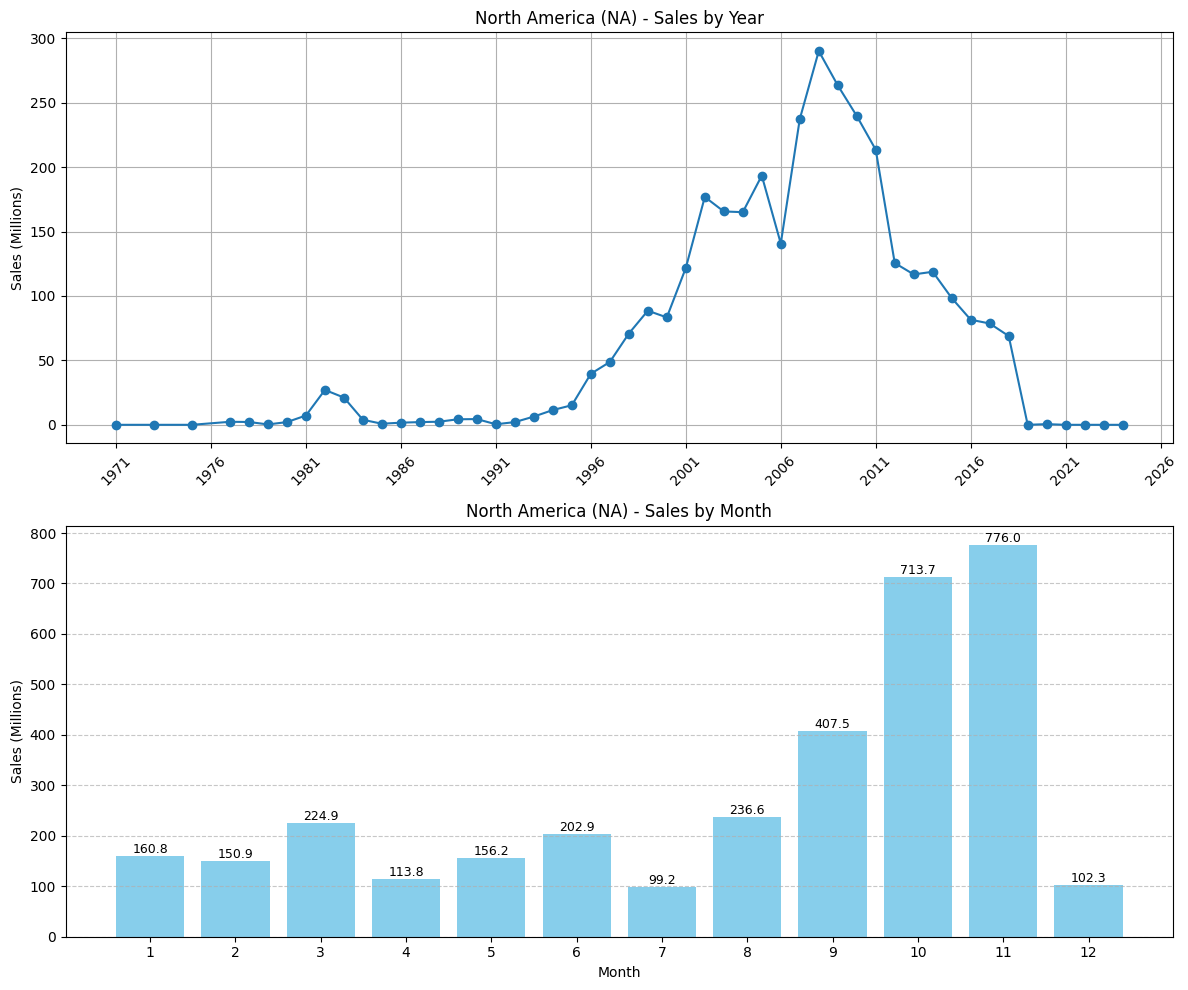

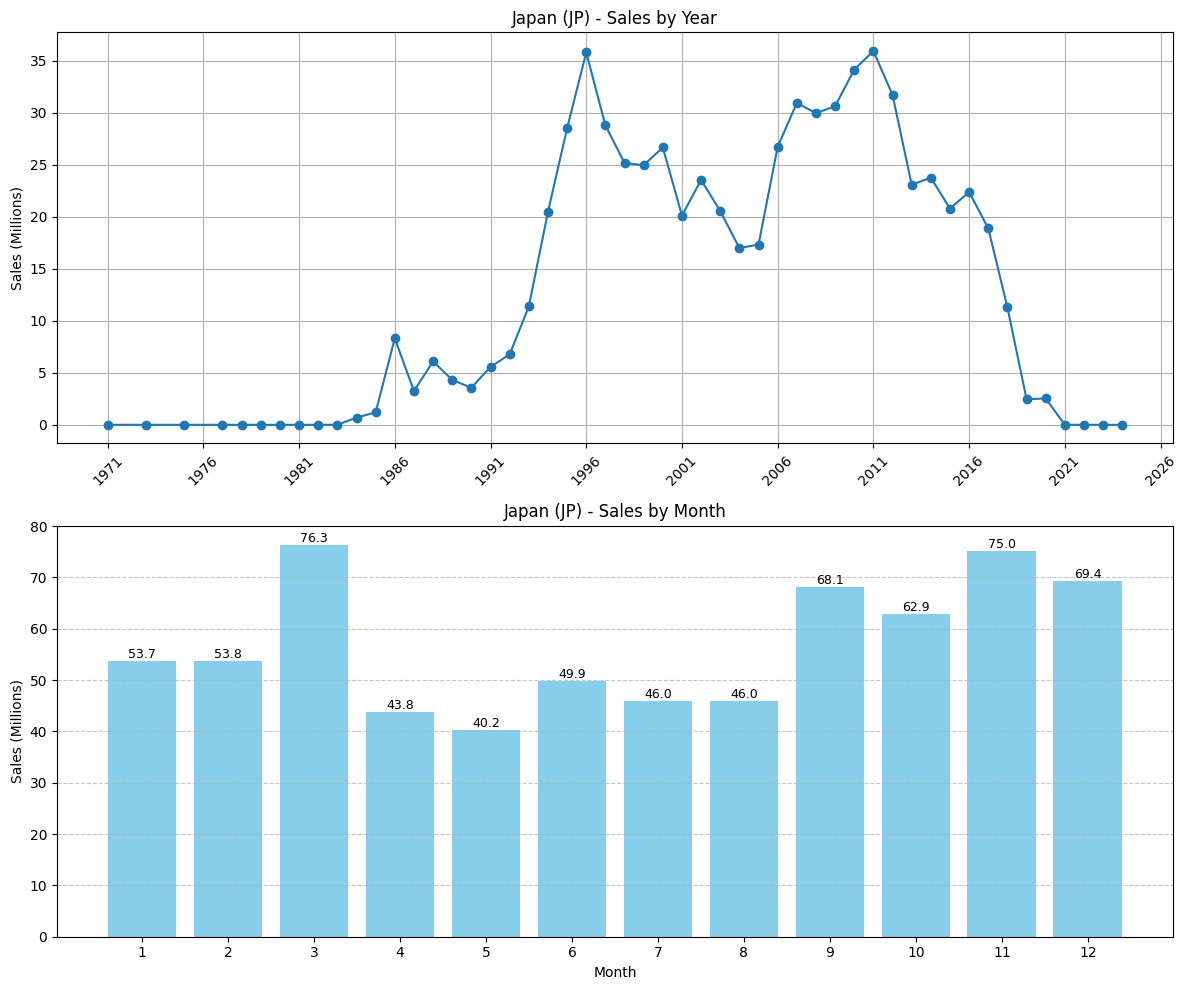

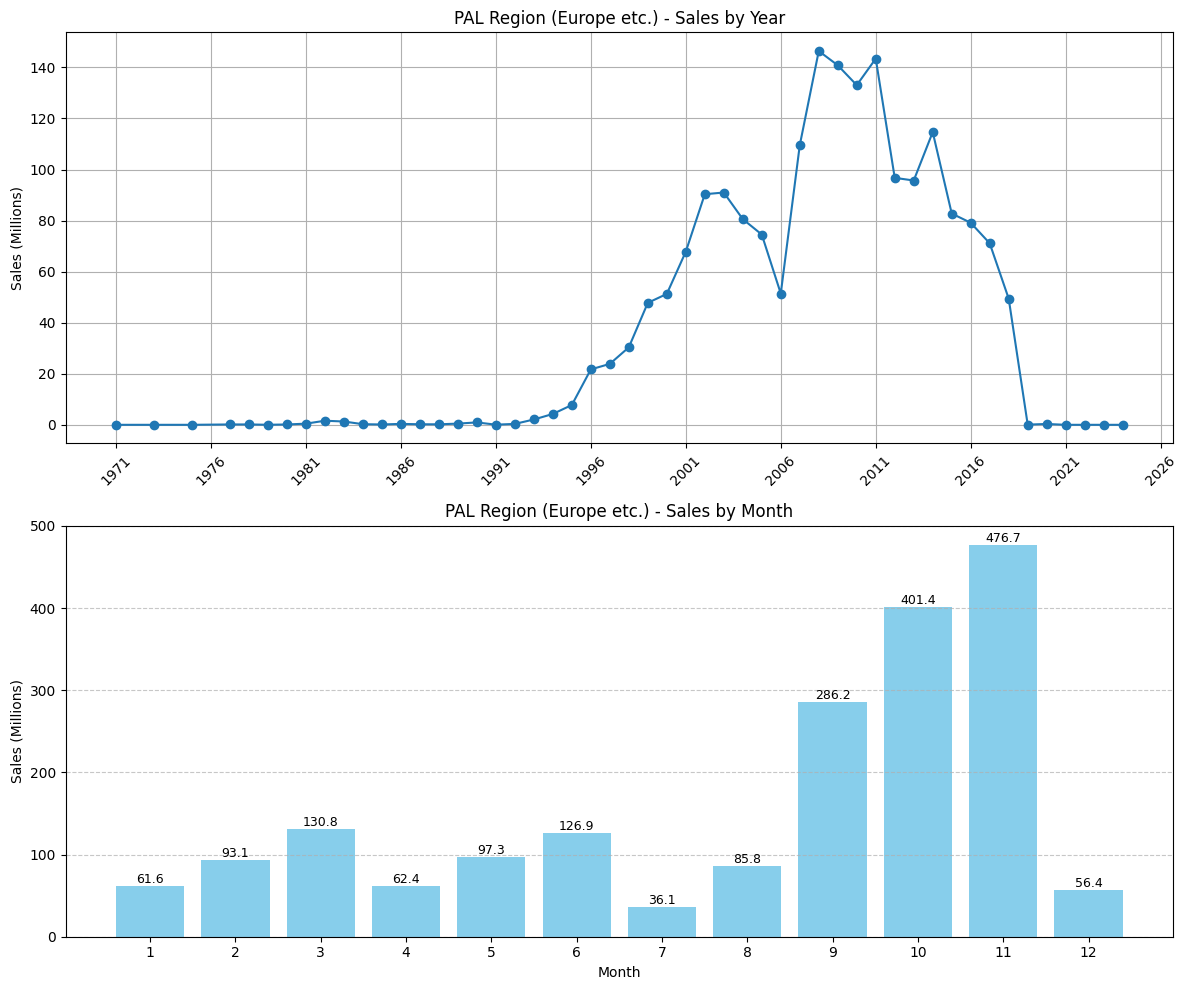

In [14]:
regions = {
    'na_sales(mil)': 'North America (NA)',
    'jp_sales(mil)': 'Japan (JP)',
    'pal_sales(mil)': 'PAL Region (Europe etc.)'
}

yearly_data = df.groupby('release_year')[list(regions.keys())].sum().sort_index()
monthly_data = df.groupby('release_month')[list(regions.keys())].sum().sort_index()

for col, name in regions.items():
    plt.figure(figsize=(12, 10))

    plt.subplot(2, 1, 1)
    plt.plot(yearly_data.index, yearly_data[col], marker='o', linestyle='-', label=name)
    plt.title(f'{name} - Sales by Year')
    plt.ylabel('Sales (Millions)')
    plt.grid(True)
    plt.xticks(np.arange(int(yearly_data.index.min()), int(yearly_data.index.max()) + 5, 5), rotation=45)

    plt.subplot(2, 1, 2)
    bars = plt.bar(monthly_data.index, monthly_data[col], color='skyblue')
    plt.title(f'{name} - Sales by Month')
    plt.xlabel('Month')
    plt.ylabel('Sales (Millions)')
    plt.xticks(range(1, 13))
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height,
                 f'{height:.1f}',
                 ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()

In Japan, the sales season appears to be longer than in other regions.

## Deep Dive: Sales by Category
Comparing total sales and average critic scores for Consoles, Genres, and Publishers.

--- CONSOLE ANALYSIS ---


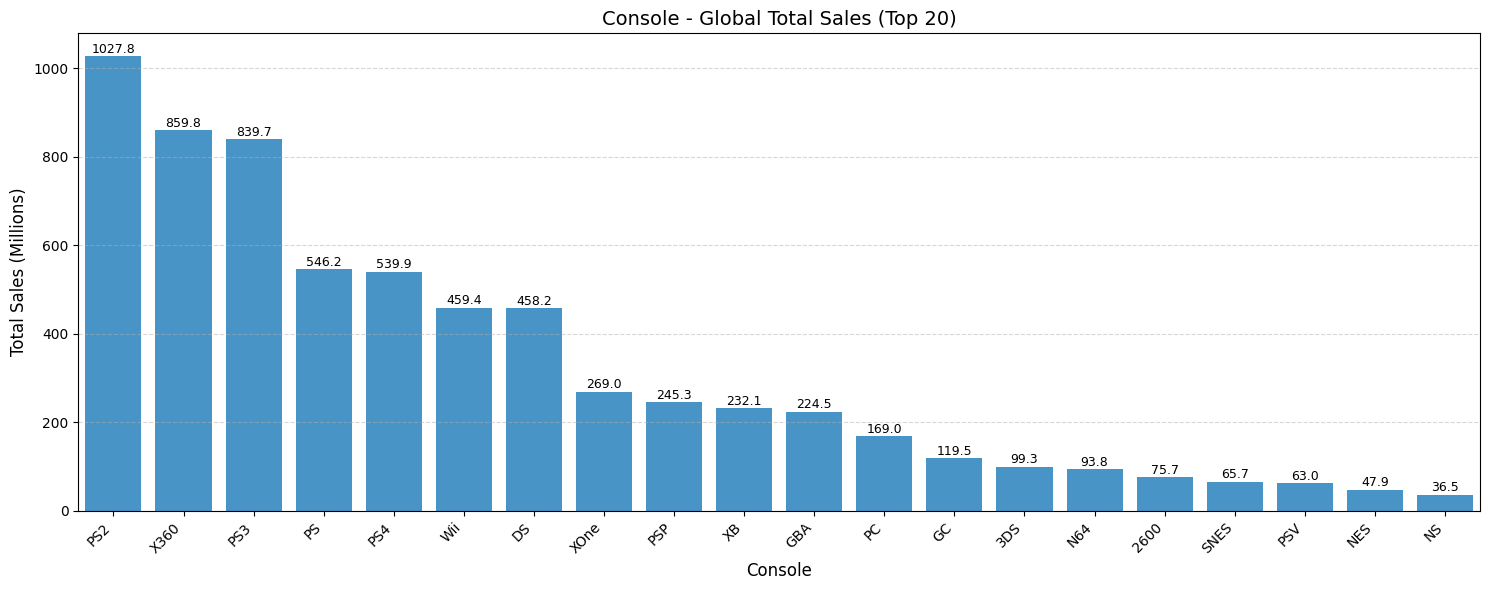

--- GENRE ANALYSIS ---


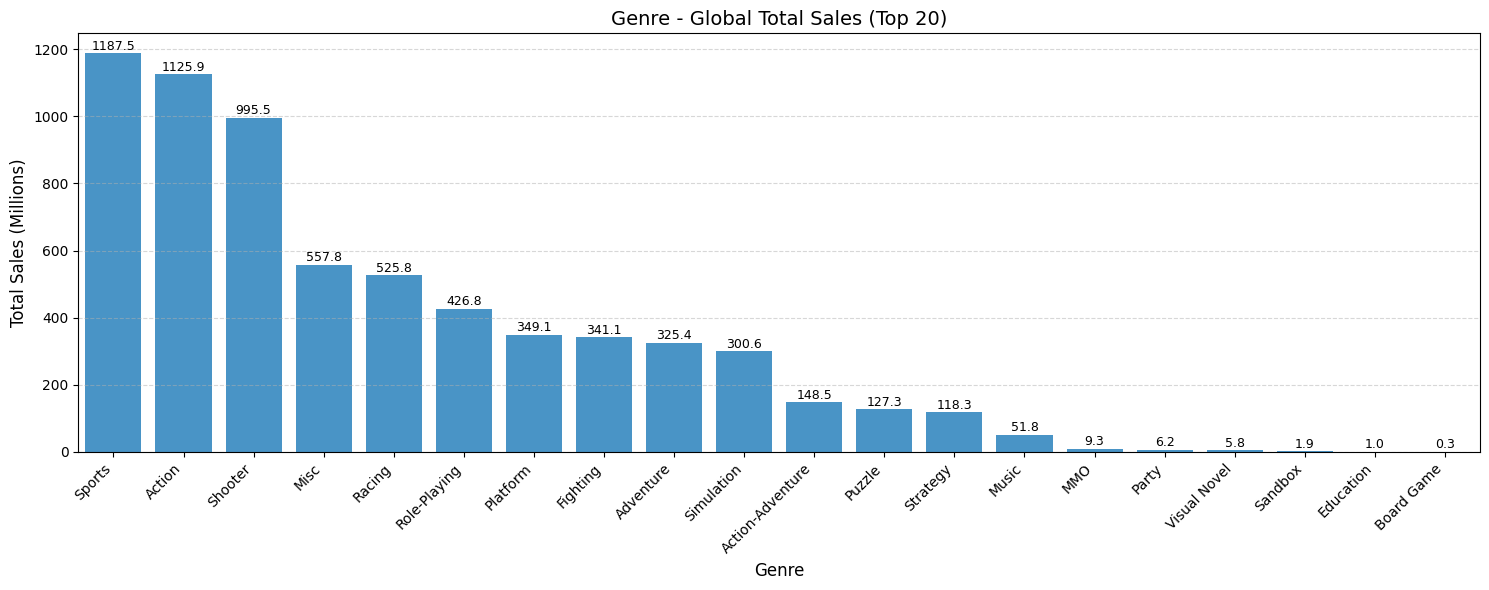

--- PUBLISHER ANALYSIS ---


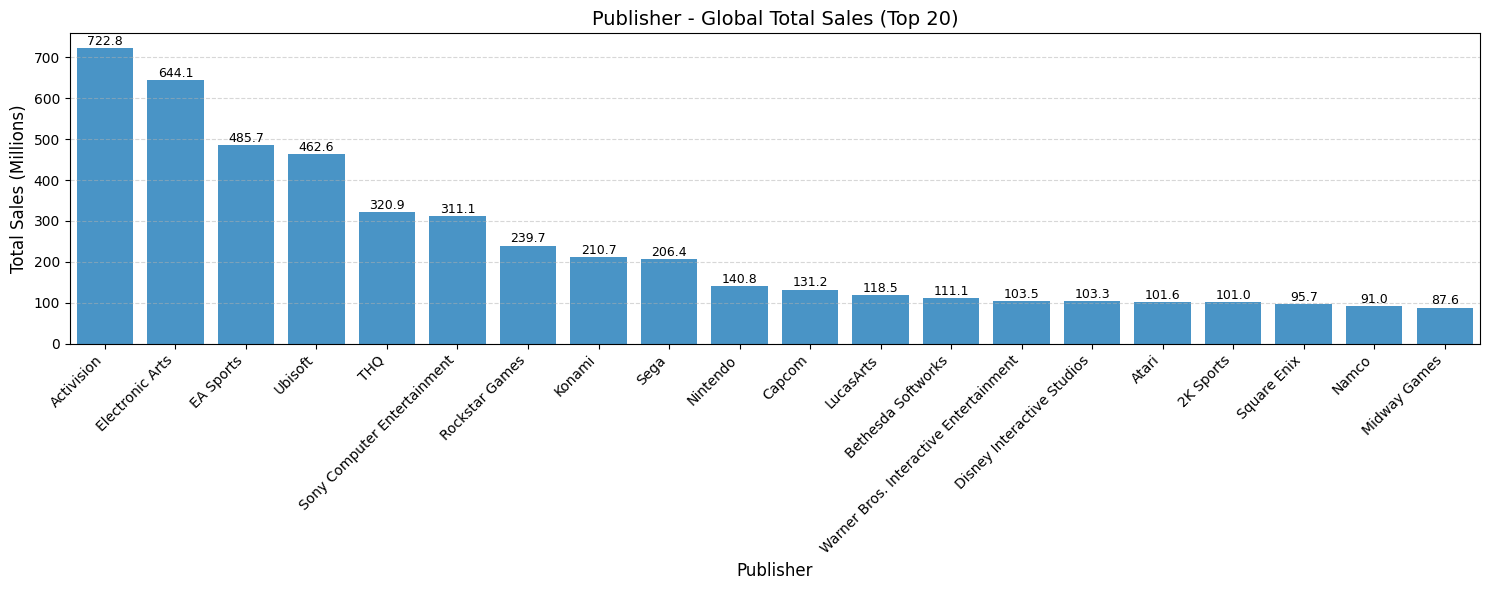

In [15]:
def plot_separate_metrics(category_col, top_n=20):

    grouped = df.groupby(category_col).agg({
        'total_sales(mil)': 'sum',
        'critic_score': 'mean'
    }).sort_values(by='total_sales(mil)', ascending=False).head(top_n)

    plt.figure(figsize=(15, 6))
    ax1 = sns.barplot(x=grouped.index, y=grouped['total_sales(mil)'], color='#3498db')
    plt.title(f'{category_col.capitalize()} - Global Total Sales (Top {top_n})', fontsize=14)
    plt.ylabel('Total Sales (Millions)', fontsize=12)
    plt.xlabel(category_col.capitalize(), fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    for p in ax1.patches:
        height = p.get_height()
        ax1.annotate(f'{height:.1f}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='center', xytext=(0, 5),
                     textcoords='offset points', fontsize=9, color='black')
    plt.tight_layout()
    plt.show()

print("--- CONSOLE ANALYSIS ---")
plot_separate_metrics('console', top_n=20)

print("--- GENRE ANALYSIS ---")
plot_separate_metrics('genre', top_n=20)

print("--- PUBLISHER ANALYSIS ---")
plot_separate_metrics('publisher', top_n=20)

--- SCORE DISTRIBUTION ANALYSIS ---


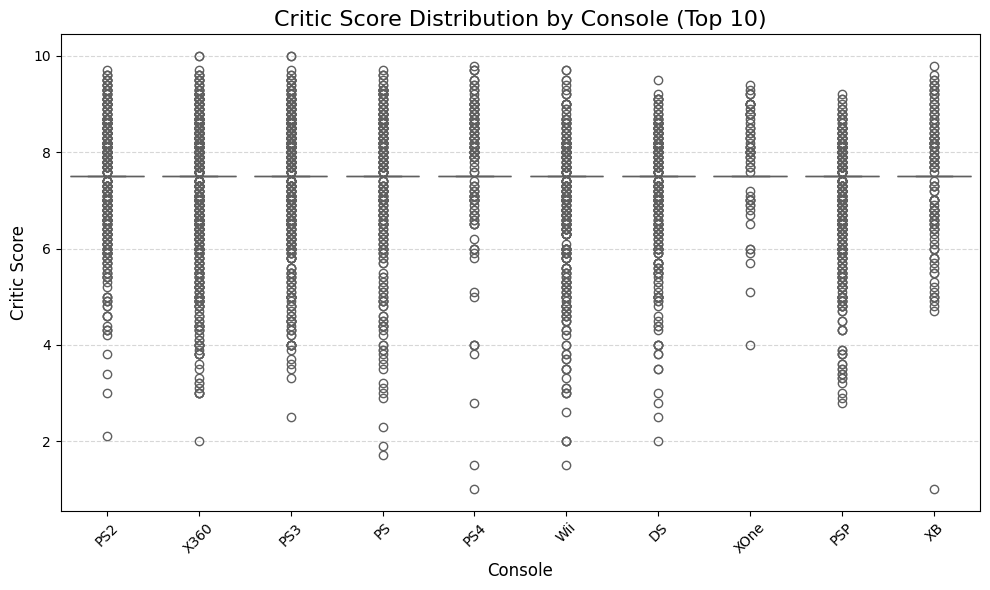

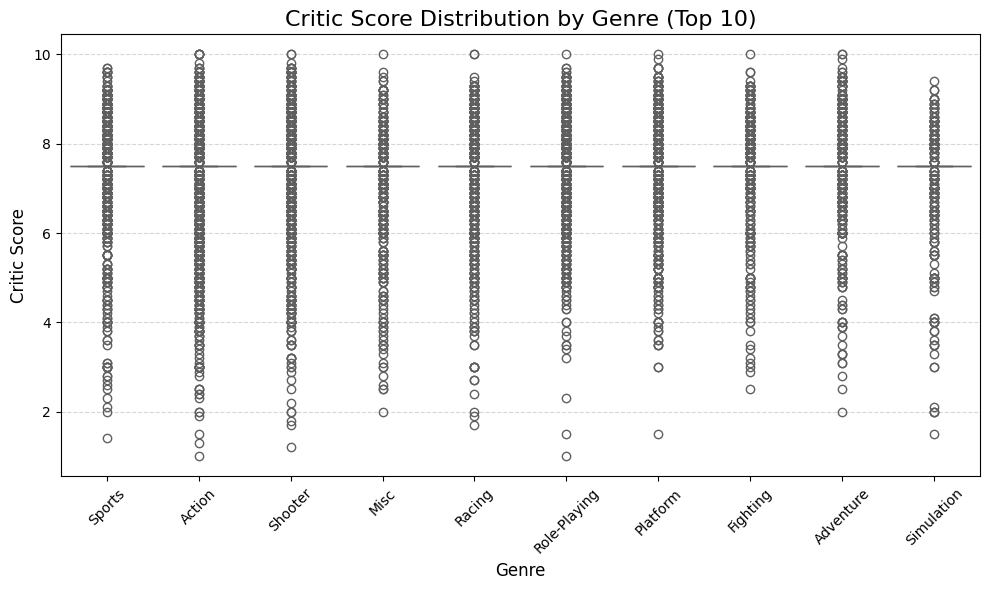

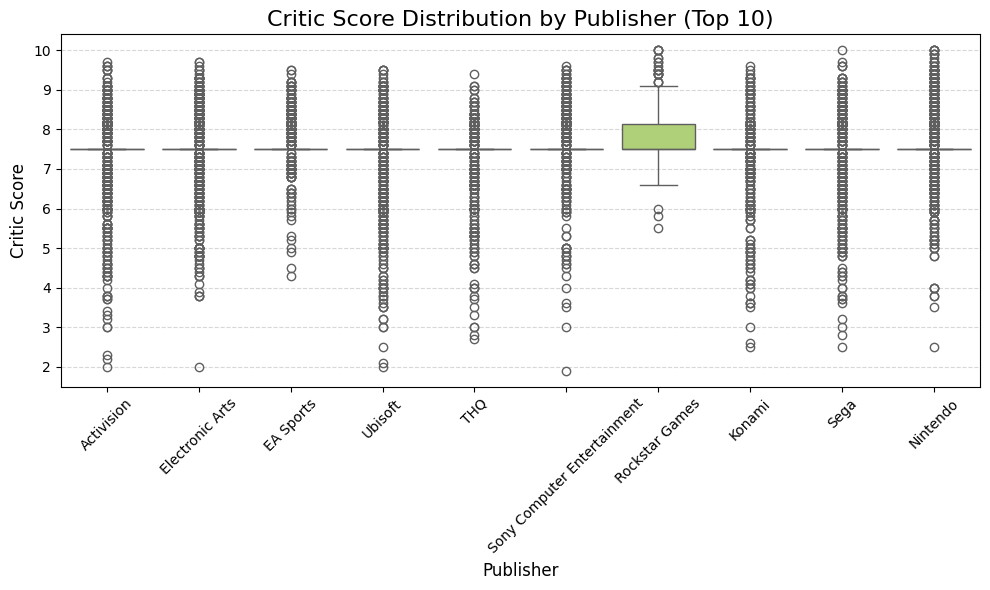

In [16]:
def plot_score_distribution(category_col, top_n=10):

    top_categories = df.groupby(category_col)['total_sales(mil)'].sum().sort_values(ascending=False).head(top_n).index
    filtered_df = df[df[category_col].isin(top_categories)]
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=category_col, y='critic_score', data=filtered_df, order=top_categories, palette="Set3")

    plt.title(f'Critic Score Distribution by {category_col.capitalize()} (Top {top_n})', fontsize=16)
    plt.ylabel('Critic Score', fontsize=12)
    plt.xlabel(category_col.capitalize(), fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

print("--- SCORE DISTRIBUTION ANALYSIS ---")
plot_score_distribution('console', top_n=10)
plot_score_distribution('genre', top_n=10)
plot_score_distribution('publisher', top_n=10)

Rockstar Games is the publisher that caught my attention in these charts because their scores are generally high and there's a fairly large scoring volume.

## Market Leaders: Publisher Market Share
Who owns the market? We analyze the top 10 publishers and their share of global sales using an interactive Pie Chart.

In [17]:
publisher_sales = df.groupby('publisher')['total_sales(mil)'].sum().sort_values(ascending=False)
top_10_publishers = publisher_sales.head(10).index.tolist()

labels = []
values = []
hover_texts = []

for pub in top_10_publishers:
    total_sales = publisher_sales[pub]
    
    pub_genres = df[df['publisher'] == pub].groupby('genre')['total_sales(mil)'].sum().sort_values(ascending=False)
    
    hover_str = f"<b>{pub}</b><br>Total Sales: {total_sales:.2f}M<br><br><b>Top Genres:</b><br>"
    for genre, sales in pub_genres.head(5).items():
        percent = (sales / total_sales) * 100
        hover_str += f"{genre}: %{percent:.1f}<br>"

    labels.append(pub)
    values.append(total_sales)
    hover_texts.append(hover_str)

fig = go.Figure(data=[go.Pie(
    labels=labels,
    values=values,
    hoverinfo='text',
    text=labels,
    textinfo='label+percent',
    hovertext=hover_texts,
    hole=0.3,
    marker=dict(line=dict(color='#000000', width=1))
)])

fig.update_layout(
    title_text="Top 10 Publishers Market Share & Genre Distribution",
    annotations=[dict(text='Top 10', x=0.5, y=0.5, font_size=20, showarrow=False)]
)
fig.show()

In [18]:
labels_console = []
values_console = []
hover_texts_console = []

for pub in top_10_publishers:
    
    total_sales = publisher_sales[pub]

    pub_consoles = df[df['publisher'] == pub].groupby('console')['total_sales(mil)'].sum().sort_values(ascending=False)

    hover_str = f"<b>{pub}</b><br>Total Sales: {total_sales:.2f}M<br><br><b>Top Consoles:</b><br>"

    for console, sales in pub_consoles.head(5).items():
        percent = (sales / total_sales) * 100
        hover_str += f"{console}: %{percent:.1f}<br>"

    labels_console.append(pub)
    values_console.append(total_sales)
    hover_texts_console.append(hover_str)

fig = go.Figure(data=[go.Pie(
    labels=labels_console,
    values=values_console,
    hoverinfo='text',         
    text=labels_console,      
    textinfo='label+percent',
    hovertext=hover_texts_console,
    hole=0.3,                 
    marker=dict(line=dict(color='#000000', width=1))
)])

fig.update_layout(
    title_text="Top 10 Publishers and Their Preferred Consoles",
    annotations=[dict(text='Top 10', x=0.5, y=0.5, font_size=20, showarrow=False)]
)

fig.show()

## Game Series Analysis 
Visualizing the best-selling game series (franchises) for the top publishers.

In [19]:
def extract_series(title):
    if not isinstance(title, str):
        return "Unknown"

    s = title.split(':')[0]
    s = s.split(' - ')[0]
    s = re.sub(r'\s+\d+$', '', s)

    roman_pattern = r'\s+(I|II|III|IV|V|VI|VII|VIII|IX|X|XI|XII|XIII|XIV|XV)$'
    s = re.sub(roman_pattern, '', s, flags=re.IGNORECASE)

    return s.strip()

df['series'] = df['title'].apply(extract_series)

series_data = df.groupby(['publisher', 'series'])['total_sales(mil)'].sum().reset_index()

top_publishers_list = series_data.groupby('publisher')['total_sales(mil)'].sum().sort_values(ascending=False).head(15).index.tolist()
filtered_data = series_data[series_data['publisher'].isin(top_publishers_list)]

filtered_data = filtered_data[filtered_data['total_sales(mil)'] > 1.0]

fig = px.treemap(
    filtered_data,
    path=['publisher', 'series'],
    values='total_sales(mil)',    
    color='total_sales(mil)',    
    color_continuous_scale='Viridis',
    title='Best Selling Game Series of Top 15 Publishers (Treemap)'
)

fig.update_traces(root_color="lightgrey")
fig.update_layout(margin = dict(t=50, l=25, r=25, b=25))

fig.show()

## Conclusion

In this notebook, we took a deep dive into the video game industry's historical data. Through various visualizations and analyses, we uncovered several interesting insights:

**The Golden Era:** The industry saw a massive boom in the mid-to-late 2000s (around 2005-2010), with a significant volume of game releases.
**Critics Matter (Mostly):** While there is a correlation between high critic scores and sales, we also observed that some games achieve massive commercial success purely through brand power and marketing, even with average scores.